![Banner](./img/AI_Special_Program_Banner.jpg)  


# Day 2 Exercise Pandas
# Exercise for Pandas 1 - Movie Data
---

In this exercise, you will examine the movie data set shown here in more detail. You are free to decide which aspects you want to look at. Here are a few possible questions (*increasing difficulty*):
* Which directors are most frequently represented?
* Who are the 5 most frequent leading actors?
* Is there a connection between revenue and the rating?
* Is there a connection between revenue and length?
* Which films are controversial? Consideration of the discrepancy between Metascore and IMDB rating
* Who are the most successful actors and actresses (highest grossing)?
* What are the most lucrative genres? 
  
Use a graphical representation of your results when it ist useful.

You may need a few more Pandas tools for your analyses, which we have explicitly **not** covered in this learning unit. Here is a short list of practical functions:
* [.nlargest()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nlargest.html) - Returns the $n$-largest values
* [.sort_values()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html) - Sorts along an axis
* [.plot()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.html) - For creating plots and visualizations
* [.value_counts()](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html) - Returns the frequency of values
* [.apply()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.apply.html) - Application of a function along an axis of the DataFrame
* [.groupby()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html) - Grouping of values

Remember that *Google* and *ChatGPT* are valuable tools to search for related problems or to get suggestions for solutions. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

movies = pd.read_csv('./data/imdb_ratings.csv')
movies.head()

,Rank,Title,Genre,Description,Director,Actors,Year,Runtime (Minutes),Rating,Votes,Revenue (Millions),Metascore
0,1,Guardians of the Galaxy,"Action,Adventure,Sci-Fi",A group of intergalactic criminals are forced ...,James Gunn,"Chris Pratt, Vin Diesel, Bradley Cooper, Zoe S...",2014,121,8.1,757074,333.13,76.0
1,2,Prometheus,"Adventure,Mystery,Sci-Fi","Following clues to the origin of mankind, a te...",Ridley Scott,"Noomi Rapace, Logan Marshall-Green, Michael Fa...",2012,124,7.0,485820,126.46,65.0
2,3,Split,"Horror,Thriller",Three girls are kidnapped by a man with a diag...,M. Night Shyamalan,"James McAvoy, Anya Taylor-Joy, Haley Lu Richar...",2016,117,7.3,157606,138.12,62.0
3,4,Sing,"Animation,Comedy,Family","In a city of humanoid animals, a hustling thea...",Christophe Lourdelet,"Matthew McConaughey,Reese Witherspoon, Seth Ma...",2016,108,7.2,60545,270.32,59.0
4,5,Suicide Squad,"Action,Adventure,Fantasy",A secret government agency recruits some of th...,David Ayer,"Will Smith, Jared Leto, Margot Robbie, Viola D...",2016,123,6.2,393727,325.02,40.0


In [2]:
movies.info()
movies.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Rank                1000 non-null   int64  
 1   Title               1000 non-null   str    
 2   Genre               1000 non-null   str    
 3   Description         1000 non-null   str    
 4   Director            1000 non-null   str    
 5   Actors              1000 non-null   str    
 6   Year                1000 non-null   int64  
 7   Runtime (Minutes)   1000 non-null   int64  
 8   Rating              1000 non-null   float64
 9   Votes               1000 non-null   int64  
 10  Revenue (Millions)  872 non-null    float64
 11  Metascore           936 non-null    float64
dtypes: float64(3), int64(4), str(5)
memory usage: 93.9 KB


Rank                    0
Title                   0
Genre                   0
Description             0
Director                0
Actors                  0
Year                    0
Runtime (Minutes)       0
Rating                  0
Votes                   0
Revenue (Millions)    128
Metascore              64
dtype: int64

In [3]:
top_directors = movies['Director'].value_counts().head(10)
top_directors

Director
Ridley Scott          8
M. Night Shyamalan    6
David Yates           6
Paul W.S. Anderson    6
Michael Bay           6
Denis Villeneuve      5
Christopher Nolan     5
Antoine Fuqua         5
Justin Lin            5
J.J. Abrams           5
Name: count, dtype: int64

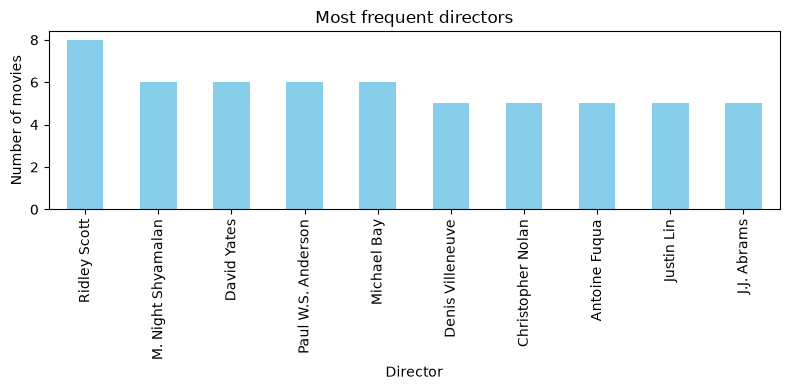

In [4]:
top_directors.plot(kind='bar', color='skyblue', figsize=(8,4))
plt.title('Most frequent directors')
plt.ylabel('Number of movies')
plt.xlabel('Director')
plt.tight_layout()
plt.show()

In [5]:
actors = movies['Actors'].str.split(',\s*').explode()
top_actors = actors.value_counts().head(5)
top_actors

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
C:\Users\psybe\AppData\Local\Temp\ipykernel_21256\1627057032.py:1: SyntaxWarning: invalid escape sequence '\s'
  actors = movies['Actors'].str.split(',\s*').explode()


Actors
Mark Wahlberg         15
Hugh Jackman          14
Christian Bale        13
Brad Pitt             13
Michael Fassbender    12
Name: count, dtype: int64

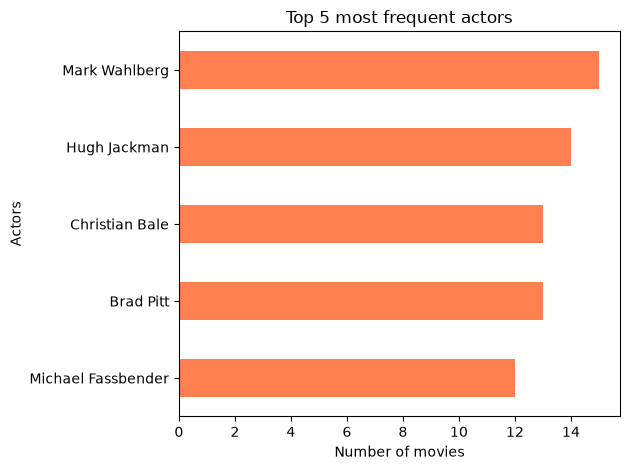

In [6]:
top_actors.plot(kind='barh', color='coral')
plt.title('Top 5 most frequent actors')
plt.xlabel('Number of movies')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

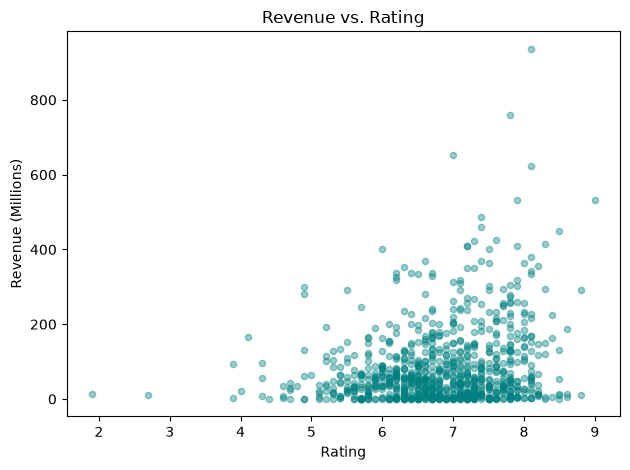

Correlation between Rating and Revenue: 0.22


In [7]:
movies.plot(kind='scatter', x='Rating', y='Revenue (Millions)', alpha=0.4, color='teal')
plt.title('Revenue vs. Rating')
plt.tight_layout()
plt.show()

corr_rating = movies['Rating'].corr(movies['Revenue (Millions)'])
print(f'Correlation between Rating and Revenue: {corr_rating:.2f}')

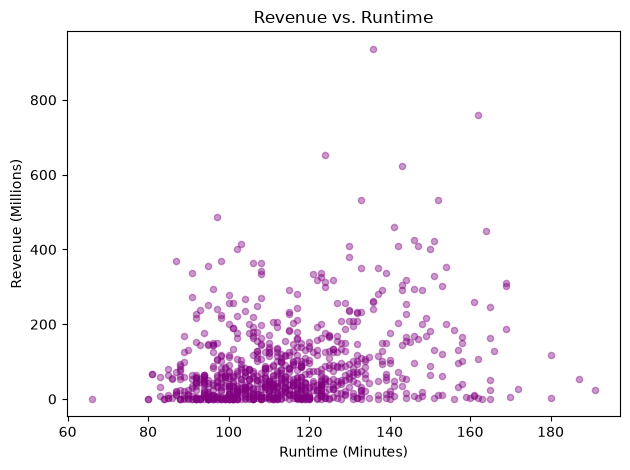

Correlation between Runtime and Revenue: 0.27


In [8]:
movies.plot(kind='scatter', x='Runtime (Minutes)', y='Revenue (Millions)', alpha=0.4, color='purple')
plt.title('Revenue vs. Runtime')
plt.tight_layout()
plt.show()

corr_runtime = movies['Runtime (Minutes)'].corr(movies['Revenue (Millions)'])
print(f'Correlation between Runtime and Revenue: {corr_runtime:.2f}')

In [9]:
movies_clean = movies.dropna(subset=['Metascore']).copy()
movies_clean['Metascore_scaled'] = movies_clean['Metascore'] / 10
movies_clean['Discrepancy'] = (movies_clean['Rating'] - movies_clean['Metascore_scaled']).abs()

most_controversial = movies_clean.nlargest(10, 'Discrepancy')[
    ['Title', 'Rating', 'Metascore_scaled', 'Discrepancy']
]
most_controversial

,Title,Rating,Metascore_scaled,Discrepancy
73,Collateral Beauty,6.8,2.3,4.5
633,Megan Is Missing,4.9,9.4,4.5
991,Taare Zameen Par,8.5,4.2,4.3
266,Dirty Grandpa,6.0,1.8,4.2
999,Nine Lives,5.3,1.1,4.2
684,Seven Pounds,7.7,3.6,4.1
452,Pandorum,6.8,2.8,4.0
498,Law Abiding Citizen,7.4,3.4,4.0
734,Mr. Church,7.7,3.7,4.0
295,The Choice,6.6,2.6,4.0


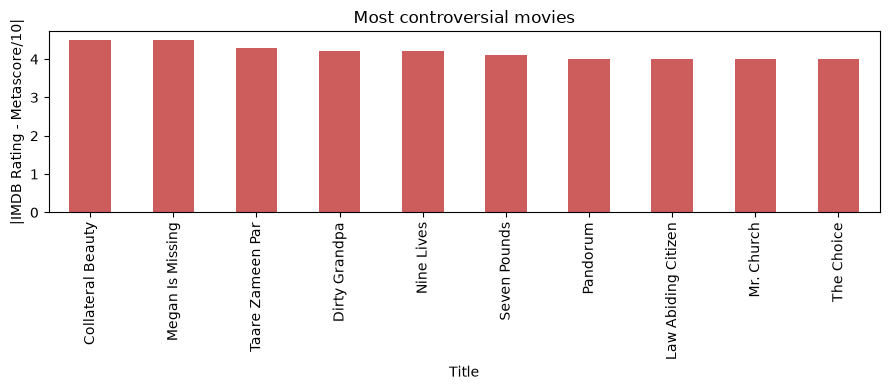

In [10]:
most_controversial.plot(kind='bar', x='Title', y='Discrepancy', color='indianred', legend=False, figsize=(9,4))
plt.ylabel('|IMDB Rating - Metascore/10|')
plt.title('Most controversial movies')
plt.tight_layout()
plt.show()

In [11]:
movies_rev = movies.dropna(subset=['Revenue (Millions)']).copy()
actor_revenue = movies_rev.assign(Actor=movies_rev['Actors'].str.split(',\s*')).explode('Actor')

top_grossing_actors = actor_revenue.groupby('Actor')['Revenue (Millions)'].sum().nlargest(10)
top_grossing_actors

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
C:\Users\psybe\AppData\Local\Temp\ipykernel_21256\1500911852.py:2: SyntaxWarning: invalid escape sequence '\s'
  actor_revenue = movies_rev.assign(Actor=movies_rev['Actors'].str.split(',\s*')).explode('Actor')


Actor
Robert Downey Jr.     3147.37
Jennifer Lawrence     2191.82
Chris Evans           1949.01
Scarlett Johansson    1874.97
Johnny Depp           1789.20
Shia LaBeouf          1695.93
Christian Bale        1653.19
Anne Hathaway         1647.47
Liam Hemsworth        1641.60
Dwayne Johnson        1598.09
Name: Revenue (Millions), dtype: float64

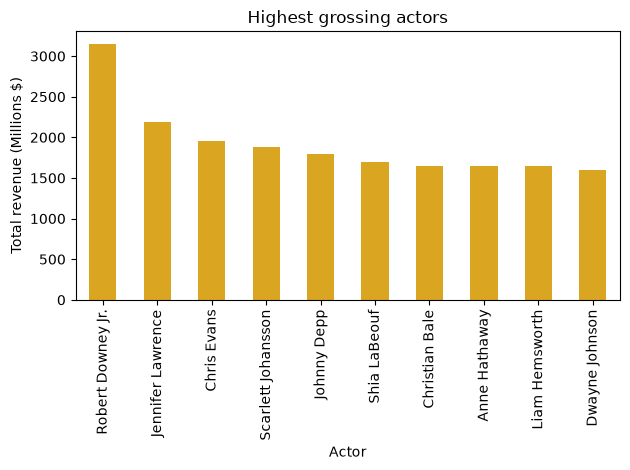

In [12]:
top_grossing_actors.plot(kind='bar', color='goldenrod')
plt.ylabel('Total revenue (Millions $)')
plt.title('Highest grossing actors')
plt.tight_layout()
plt.show()

In [13]:
genre_revenue = movies_rev.assign(Genre=movies_rev['Genre'].str.split(',')).explode('Genre')
lucrative_genres = genre_revenue.groupby('Genre')['Revenue (Millions)'].mean().sort_values(ascending=False)
lucrative_genres

Genre
Animation    191.223404
Adventure    154.177024
Sci-Fi       135.552545
Fantasy      131.850108
Family       126.175714
Action       124.494476
Western      111.824000
Musical       81.642000
Comedy        75.750784
Thriller      69.577255
Sport         65.042500
Crime         61.804769
Biography     55.801600
Mystery       54.627640
War           53.433000
History       52.923846
Drama         49.844205
Music         47.070000
Romance       42.503023
Horror        36.705269
Name: Revenue (Millions), dtype: float64

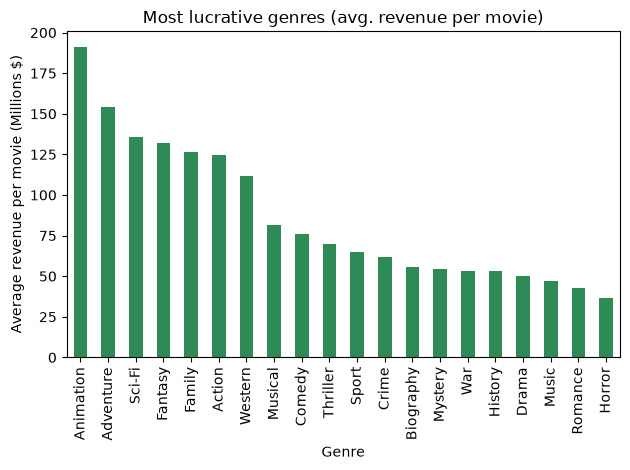

In [14]:
lucrative_genres.plot(kind='bar', color='seagreen')
plt.ylabel('Average revenue per movie (Millions $)')
plt.title('Most lucrative genres (avg. revenue per movie)')
plt.tight_layout()
plt.show()

# Exercise for Pandas 2 - Electronics Retailer
---

In this exercise, you are to analyze the sales of an electronics retailer from 2019. The retailer saves its sales data for each month (12 files) individually in a `csv` file. These files can be found under `./data/`. As the data comes from a relational database, the *date* and *product* of each individual sale are coded with an *ID*. The mapping for the products and date entries can be found under `./data/ID Files/` as `date.csv` and `product.csv`.

The retailer asks you to answer the following questions:

* Which months have the strongest sales?
* Which products were sold most frequently?

**Notes:**

* Before you can analyze the data, you should first merge it. Start by displaying all csv data in a DataFrame.
* To calculate the months, you can familiarize yourself with [pd.to_datetime](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.to_datetime.html)

In [15]:
import glob

sales_files = sorted(glob.glob('./data/sales_*.csv'))
sales_files

['./data\\sales_apr_19.csv',
 './data\\sales_aug_19.csv',
 './data\\sales_dec_19.csv',
 './data\\sales_feb_19.csv',
 './data\\sales_jan_19.csv',
 './data\\sales_jul_19.csv',
 './data\\sales_jun_19.csv',
 './data\\sales_mai_19.csv',
 './data\\sales_mrz_19.csv',
 './data\\sales_nov_19.csv',
 './data\\sales_oct_19.csv',
 './data\\sales_sep_19.csv']

In [16]:
sales = pd.concat([pd.read_csv(f) for f in sales_files], ignore_index=True)
sales.head()

,Order ID,Product ID,Quantity Ordered,Price Each,Date,Purchase Address
0,162358,8,1,300.00,90,"444 12th St, New York City, NY 10001"
1,162541,5,2,2.99,90,"672 2nd St, Atlanta, GA 30301"
2,165007,3,1,379.99,90,"389 Willow St, New York City, NY 10001"
3,165622,12,1,14.95,90,"65 Madison St, Boston, MA 02215"
4,166250,12,1,14.95,90,"159 Walnut St, Los Angeles, CA 90001"


In [17]:
sales.shape

(185950, 6)

In [18]:
date_map = pd.read_csv('./data/ID Files/date.csv')
product_map = pd.read_csv('./data/ID Files/product.csv')

date_map.head()

,Date,Date ID
0,2019-01-01,0
1,2019-01-02,1
2,2019-01-03,2
3,2019-01-04,3
4,2019-01-05,4


In [19]:
product_map.head()

,Product,Product ID
0,20in Monitor,0
1,27in 4K Gaming Monitor,1
2,27in FHD Monitor,2
3,34in Ultrawide Monitor,3
4,AA Batteries (4-pack),4


In [20]:
sales = sales.rename(columns={'Date': 'Date ID'})
sales = sales.merge(date_map, on='Date ID', how='left')
sales = sales.merge(product_map, on='Product ID', how='left')

sales['Date'] = pd.to_datetime(sales['Date'])
sales['Revenue'] = sales['Quantity Ordered'] * sales['Price Each']
sales = sales.drop(columns=['Date ID', 'Product ID'])
sales.head()

,Order ID,Quantity Ordered,Price Each,Purchase Address,Date,Product,Revenue
0,162358,1,300.00,"444 12th St, New York City, NY 10001",2019-04-01,Flatscreen TV,300.00
1,162541,2,2.99,"672 2nd St, Atlanta, GA 30301",2019-04-01,AAA Batteries (4-pack),5.98
2,165007,1,379.99,"389 Willow St, New York City, NY 10001",2019-04-01,34in Ultrawide Monitor,379.99
3,165622,1,14.95,"65 Madison St, Boston, MA 02215",2019-04-01,Lightning Charging Cable,14.95
4,166250,1,14.95,"159 Walnut St, Los Angeles, CA 90001",2019-04-01,Lightning Charging Cable,14.95


In [21]:
monthly_revenue = sales.groupby(sales['Date'].dt.month)['Revenue'].sum()
monthly_revenue

Date
1     1822256.73
2     2202022.42
3     2807100.38
4     3390670.24
5     3152606.75
6     2577802.26
7     2647775.76
8     2244467.88
9     2097560.13
10    3736726.88
11    3199603.20
12    4613443.34
Name: Revenue, dtype: float64

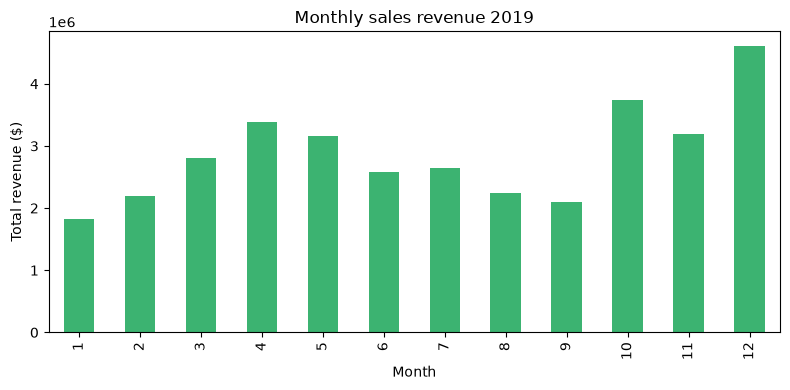

In [22]:
monthly_revenue.plot(kind='bar', color='mediumseagreen', figsize=(8,4))
plt.xlabel('Month')
plt.ylabel('Total revenue ($)')
plt.title('Monthly sales revenue 2019')
plt.tight_layout()
plt.show()

In [23]:
top_products = sales.groupby('Product')['Quantity Ordered'].sum().sort_values(ascending=False)
top_products.head(10)

Product
AAA Batteries (4-pack)        31017
AA Batteries (4-pack)         27635
USB-C Charging Cable          23975
Lightning Charging Cable      23217
Wired Headphones              20557
Apple Airpods Headphones      15661
Bose SoundSport Headphones    13457
27in FHD Monitor               7550
iPhone                         6849
27in 4K Gaming Monitor         6244
Name: Quantity Ordered, dtype: int64

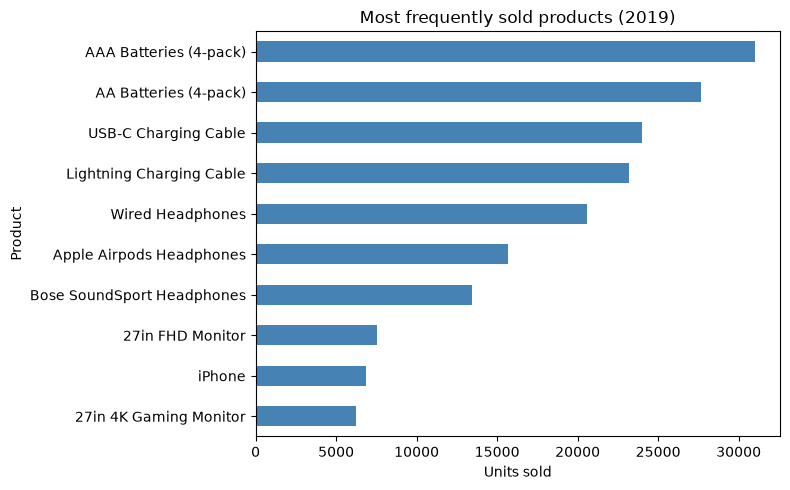

In [24]:
top_products.head(10).plot(kind='barh', color='steelblue', figsize=(8,5))
plt.xlabel('Units sold')
plt.title('Most frequently sold products (2019)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()